## D.1. Hubungkan Google Drive



In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## D.2. Import library dan atur nama gambar



In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path
from skimage import filters, morphology

FOLDER = Path('/content/drive/MyDrive/PCVK')
FILES = {
    'plat': 'plat_nomor.jpg',
    'j': 'j.png',
    'kitten': 'kitten01.jpg',
    'lily': 'lily.jpg',
    'ktp_sendiri': 'ktp_saya.jpeg',
    'ktp_fulan': 'ktp_fulan.webp',
    'ktp_teman': 'ktp_teman.jpeg',
}

for label, nama in FILES.items():
    status = 'tersedia' if (FOLDER / nama).is_file() else 'belum ditemukan'
    print(f'{label}: {nama} - {status}')

plat: plat_nomor.jpg - tersedia
j: j.png - belum ditemukan
kitten: kitten01.jpg - tersedia
lily: lily.jpg - tersedia
ktp_sendiri: ktp_saya.jpeg - tersedia
ktp_fulan: ktp_fulan.webp - tersedia
ktp_teman: ktp_teman.jpeg - tersedia


### Fungsi membaca dan menampilkan gambar

Fungsi bantu ini dipakai ulang agar setiap percobaan tetap singkat.
Jika gambar belum ditemukan, periksa nama file pada sel konfigurasi.
Gambar dibaca sebagai grayscale, kecuali saat citra warna KTP diperlukan.

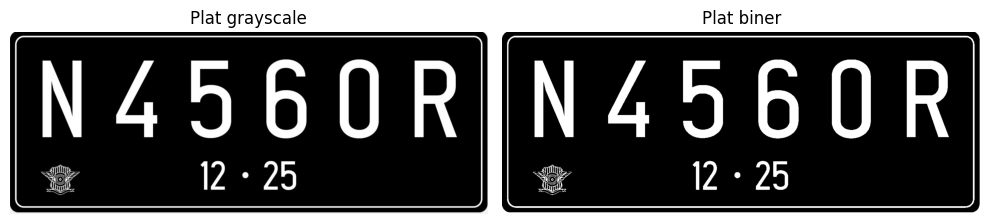

In [4]:
def baca_citra(label, grayscale=True):
    lokasi = FOLDER / FILES[label]
    mode = cv2.IMREAD_GRAYSCALE if grayscale else cv2.IMREAD_COLOR
    citra = cv2.imread(str(lokasi), mode)
    if citra is None:
        raise FileNotFoundError(f'Gambar tidak dapat dibaca: {lokasi}')
    return citra


def tampilkan(gambar, judul, kolom=3):
    baris = (len(gambar) + kolom - 1) // kolom
    plt.figure(figsize=(5 * kolom, 3.5 * baris))
    for i, (citra, nama) in enumerate(zip(gambar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if citra.ndim == 2:
            plt.imshow(citra, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(citra)  # Citra warna harus sudah RGB.
        plt.title(nama)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


plat = baca_citra('plat')
_, biner = cv2.threshold(plat, 127, 255, cv2.THRESH_BINARY)
tampilkan([plat, biner], ['Plat grayscale', 'Plat biner'], kolom=2)

## D.3. Dilasi manual dengan SE cross 3 x 3



SE cross 3 x 3:
 [[0 1 0]
 [1 1 1]
 [0 1 0]]


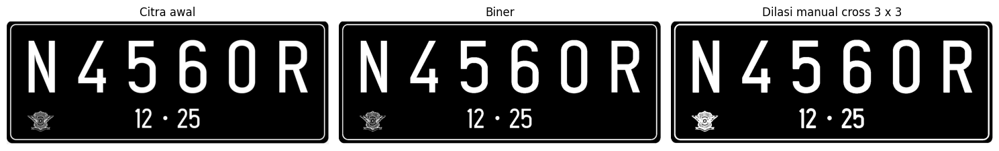

In [5]:
def dilasi_manual(citra, kernel):
    tinggi, lebar = citra.shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    citra_pad = np.pad(citra, ((ph, ph), (pw, pw)),
                       mode='constant', constant_values=0)
    hasil = np.zeros_like(citra)

    for y in range(tinggi):
        for x in range(lebar):
            area = citra_pad[y:y + kh, x:x + kw]
            hasil[y, x] = np.max(area[kernel == 1])
    return hasil


cross3 = np.array([[0, 1, 0],
                   [1, 1, 1],
                   [0, 1, 0]], dtype=np.uint8)
print('SE cross 3 x 3:\n', cross3)
dilasi_cross_manual = dilasi_manual(biner, cross3)
tampilkan([plat, biner, dilasi_cross_manual],
          ['Citra awal', 'Biner', 'Dilasi manual cross 3 x 3'])

## D.4. Dilasi dengan OpenCV



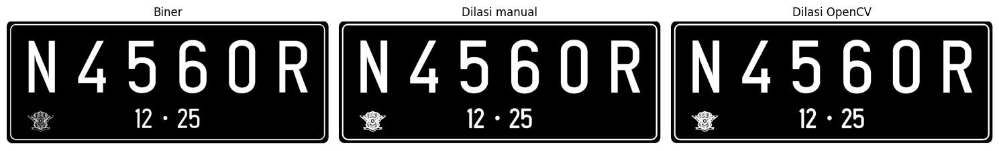

Hasil manual sama dengan OpenCV: True


In [6]:
dilasi_cross_cv = cv2.dilate(biner, cross3, iterations=1,
                             borderType=cv2.BORDER_CONSTANT, borderValue=0)
tampilkan([biner, dilasi_cross_manual, dilasi_cross_cv],
          ['Biner', 'Dilasi manual', 'Dilasi OpenCV'])
print('Hasil manual sama dengan OpenCV:',
      np.array_equal(dilasi_cross_manual, dilasi_cross_cv))

## D.5. Erosi manual dengan SE square 5 x 5



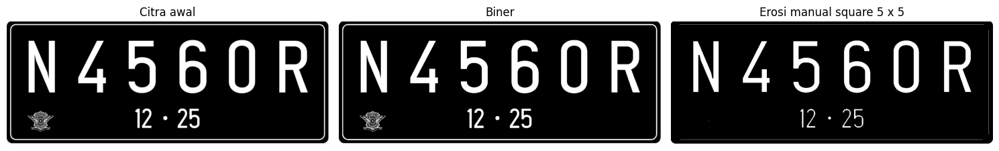

In [7]:
def erosi_manual(citra, kernel):
    tinggi, lebar = citra.shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    citra_pad = np.pad(citra, ((ph, ph), (pw, pw)),
                       mode='constant', constant_values=255)
    hasil = np.zeros_like(citra)

    for y in range(tinggi):
        for x in range(lebar):
            area = citra_pad[y:y + kh, x:x + kw]
            hasil[y, x] = np.min(area[kernel == 1])
    return hasil


square5 = np.ones((5, 5), dtype=np.uint8)
erosi_square_manual = erosi_manual(biner, square5)
tampilkan([plat, biner, erosi_square_manual],
          ['Citra awal', 'Biner', 'Erosi manual square 5 x 5'])

## D.6. Erosi dengan OpenCV



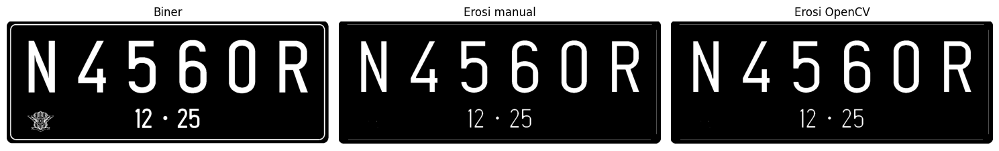

Hasil manual sama dengan OpenCV: True


In [8]:
erosi_square_cv = cv2.erode(biner, square5, iterations=1,
                            borderType=cv2.BORDER_CONSTANT, borderValue=255)
tampilkan([biner, erosi_square_manual, erosi_square_cv],
          ['Biner', 'Erosi manual', 'Erosi OpenCV'])
print('Hasil manual sama dengan OpenCV:',
      np.array_equal(erosi_square_manual, erosi_square_cv))

## D.7. Opening manual dan OpenCV, square 3 x 3



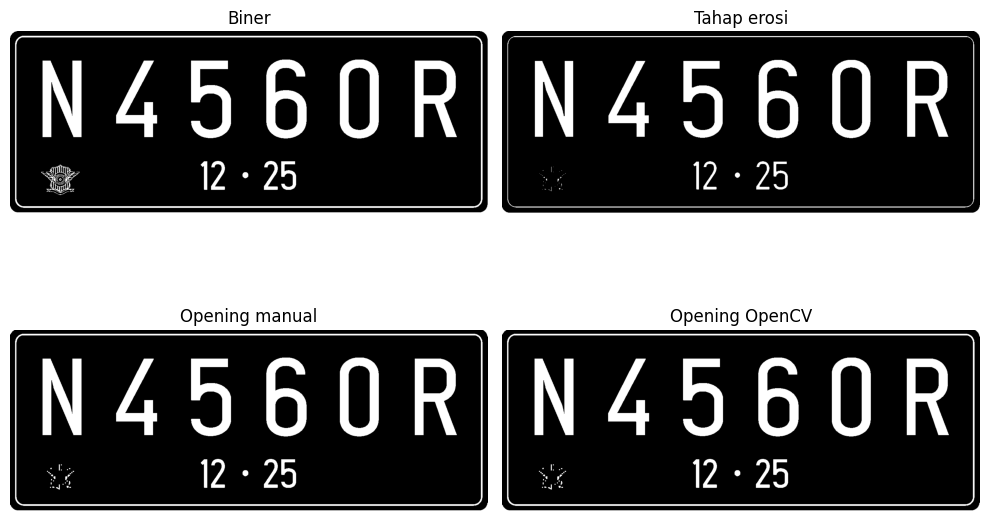

Hasil manual sama dengan OpenCV: True


In [9]:
square3 = np.ones((3, 3), dtype=np.uint8)
hasil_erosi = erosi_manual(biner, square3)
opening_manual = dilasi_manual(hasil_erosi, square3)
opening_cv = cv2.morphologyEx(biner, cv2.MORPH_OPEN, square3)

tampilkan([biner, hasil_erosi, opening_manual, opening_cv],
          ['Biner', 'Tahap erosi', 'Opening manual', 'Opening OpenCV'], kolom=2)
print('Hasil manual sama dengan OpenCV:',
      np.array_equal(opening_manual, opening_cv))

## D.8. Closing manual dan OpenCV, square 3 x 3



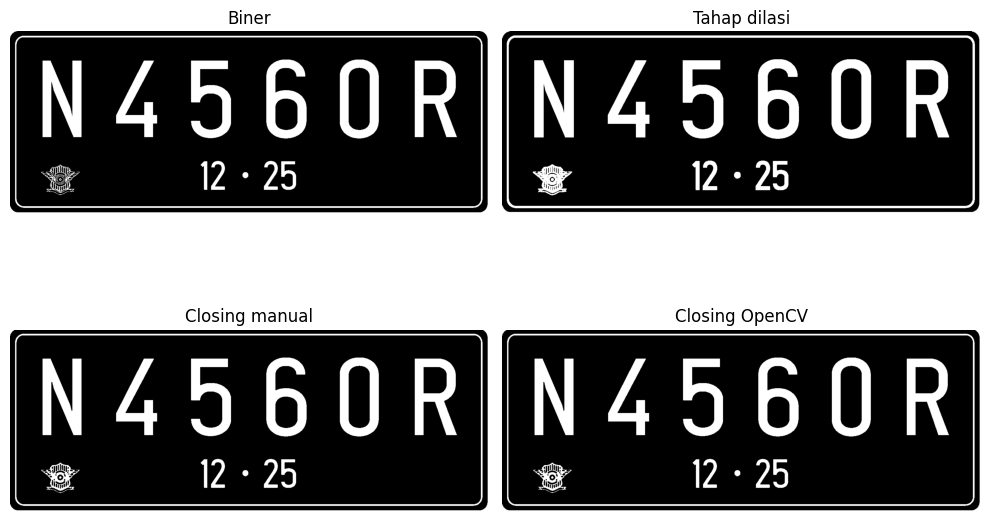

Hasil manual sama dengan OpenCV: True


In [10]:
hasil_dilasi = dilasi_manual(biner, square3)
closing_manual = erosi_manual(hasil_dilasi, square3)
closing_cv = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, square3)

tampilkan([biner, hasil_dilasi, closing_manual, closing_cv],
          ['Biner', 'Tahap dilasi', 'Closing manual', 'Closing OpenCV'], kolom=2)
print('Hasil manual sama dengan OpenCV:',
      np.array_equal(closing_manual, closing_cv))

## D.9. Dilasi cross 3 x 3 dan 5 x 5



Cross 3 x 3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Cross 5 x 5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


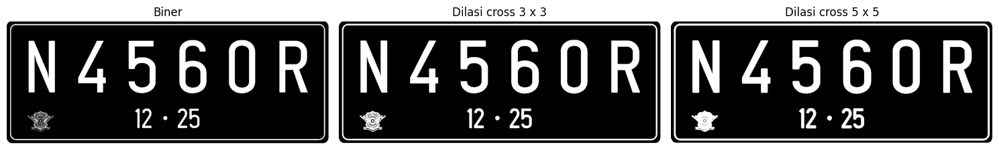

In [11]:
gambar = [biner]
judul = ['Biner']
for ukuran in [3, 5]:
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (ukuran, ukuran))
    print(f'Cross {ukuran} x {ukuran}:\n{kernel}')
    hasil = dilasi_manual(biner, kernel)
    gambar.append(hasil)
    judul.append(f'Dilasi cross {ukuran} x {ukuran}')
tampilkan(gambar, judul)

## D.10. Dilasi circular 3 x 3 dan 5 x 5



Circular 3 x 3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Circular 5 x 5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


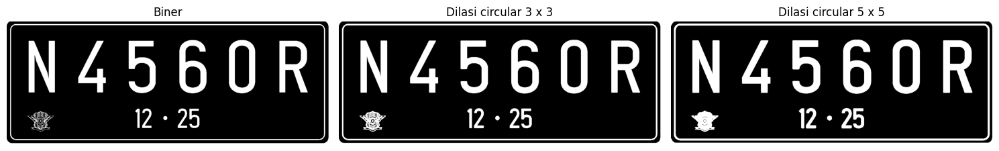

In [12]:
gambar = [biner]
judul = ['Biner']
for ukuran in [3, 5]:
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ukuran, ukuran))
    print(f'Circular {ukuran} x {ukuran}:\n{kernel}')
    gambar.append(dilasi_manual(biner, kernel))
    judul.append(f'Dilasi circular {ukuran} x {ukuran}')
tampilkan(gambar, judul)

## D.11. Erosi rectangle 3 x 5 dan 5 x 7



Rectangle 3 x 5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
Rectangle 5 x 7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]


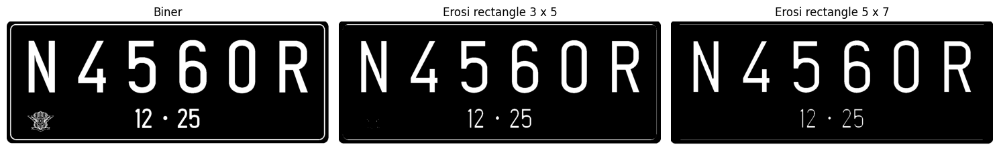

In [13]:
gambar = [biner]
judul = ['Biner']
for tinggi, lebar in [(3, 5), (5, 7)]:
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (lebar, tinggi))
    print(f'Rectangle {tinggi} x {lebar}:\n{kernel}')
    gambar.append(erosi_manual(biner, kernel))
    judul.append(f'Erosi rectangle {tinggi} x {lebar}')
tampilkan(gambar, judul)

## D.12. Erosi garis vertikal panjang 3 dan 5 pada j.png



Garis vertikal 3:
[[1]
 [1]
 [1]]
Garis vertikal 5:
[[1]
 [1]
 [1]
 [1]
 [1]]


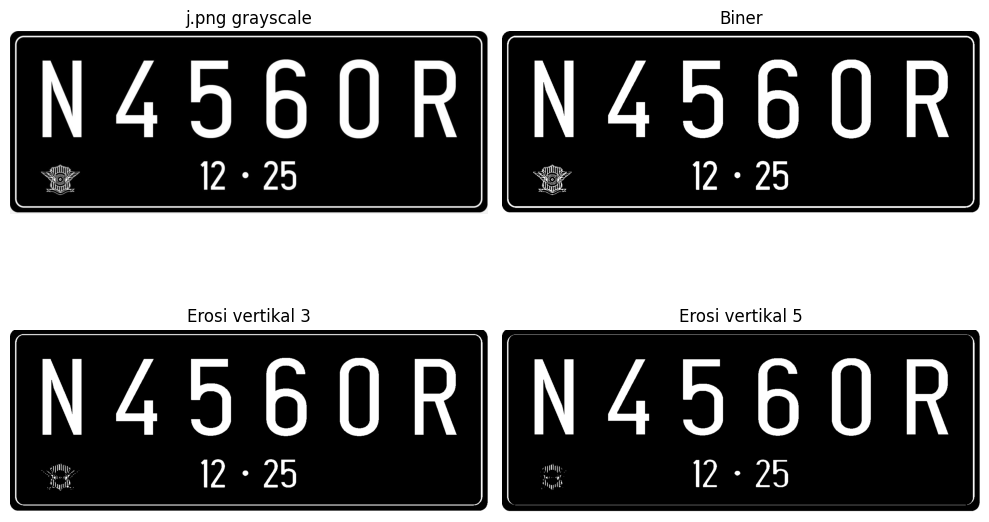

In [17]:
citra_j = baca_citra('plat')
_, biner_j = cv2.threshold(citra_j, 127, 255, cv2.THRESH_BINARY)
gambar = [citra_j, biner_j]
judul = ['j.png grayscale', 'Biner']
for panjang in [3, 5]:
    kernel = np.ones((panjang, 1), dtype=np.uint8)
    print(f'Garis vertikal {panjang}:\n{kernel}')
    gambar.append(erosi_manual(biner_j, kernel))
    judul.append(f'Erosi vertikal {panjang}')
tampilkan(gambar, judul, kolom=2)

## D.13. Top-hat



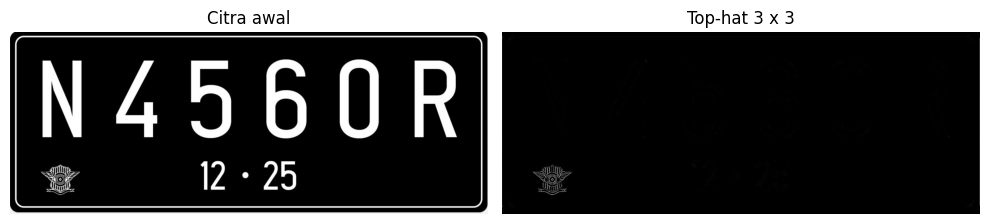

In [18]:
tophat = cv2.morphologyEx(plat, cv2.MORPH_TOPHAT, square3)
tampilkan([plat, tophat], ['Citra awal', 'Top-hat 3 x 3'], kolom=2)

## D.14. Black-hat / bottom-hat



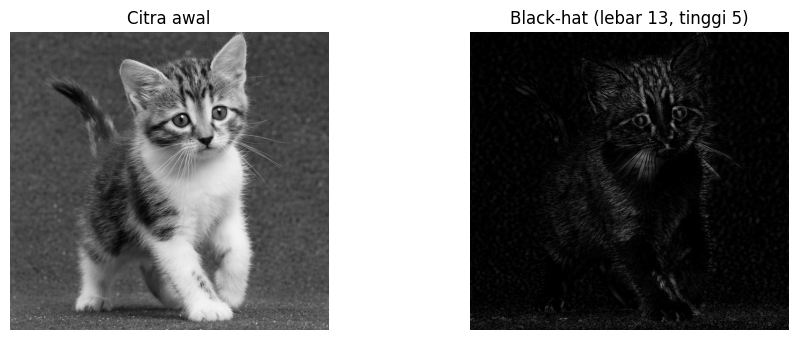

In [19]:
kitten = baca_citra('kitten')
kernel_blackhat = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(kitten, cv2.MORPH_BLACKHAT, kernel_blackhat)
tampilkan([kitten, blackhat], ['Citra awal', 'Black-hat (lebar 13, tinggi 5)'],
          kolom=2)

## D.15. Skeleton



Ambang Triangle: 253


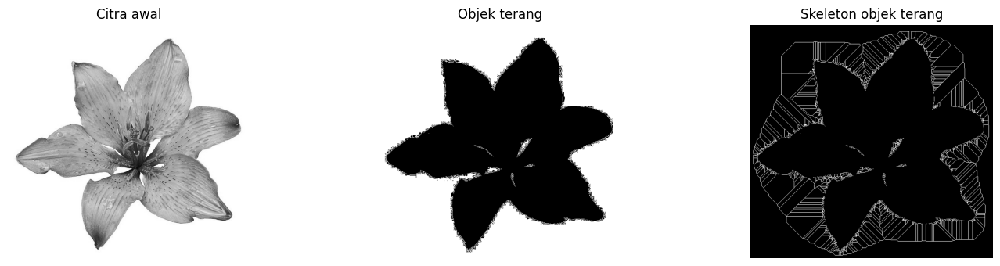

In [20]:
lily = baca_citra('lily')
ambang_lily = filters.threshold_triangle(lily)
objek_terang = lily > ambang_lily
skeleton_terang = morphology.skeletonize(objek_terang)

print('Ambang Triangle:', ambang_lily)
tampilkan([lily, objek_terang.astype(np.uint8) * 255,
           skeleton_terang.astype(np.uint8) * 255],
          ['Citra awal', 'Objek terang', 'Skeleton objek terang'])

## D.16. Skeleton inverse



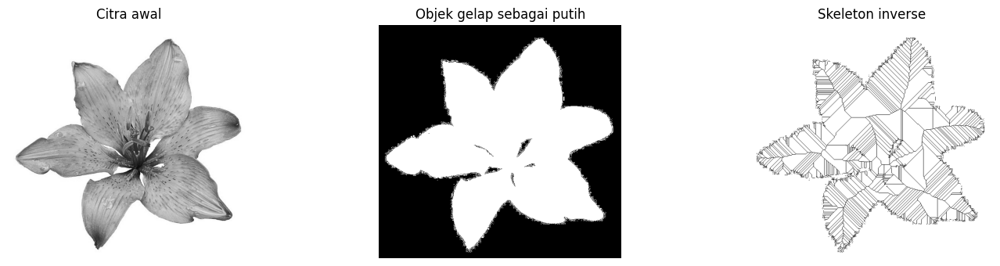

In [21]:
objek_gelap = lily < ambang_lily
skeleton_gelap = morphology.skeletonize(objek_gelap)
skeleton_inverse = 255 - skeleton_gelap.astype(np.uint8) * 255

tampilkan([lily, objek_gelap.astype(np.uint8) * 255, skeleton_inverse],
          ['Citra awal', 'Objek gelap sebagai putih', 'Skeleton inverse'])

## D.17. Bagian berjudul Thickening pada modul



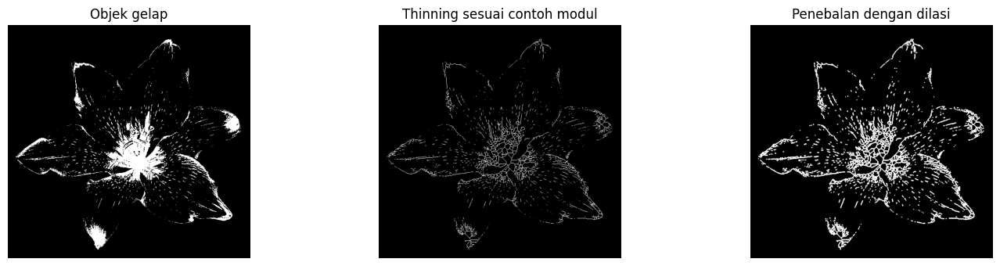

In [22]:
objek = (lily / 255.0) < 0.5
hasil_thin = morphology.thin(objek)
thin_uint8 = hasil_thin.astype(np.uint8) * 255
hasil_tebal = cv2.dilate(thin_uint8, cross3, iterations=1)

tampilkan([objek.astype(np.uint8) * 255, thin_uint8, hasil_tebal],
          ['Objek gelap', 'Thinning sesuai contoh modul', 'Penebalan dengan dilasi'])

## E. Tugas praktikum: morfologi pada citra KTP dari Modul 7



KTP sendiri: ukuran (645, 1024), ambang Otsu = 127


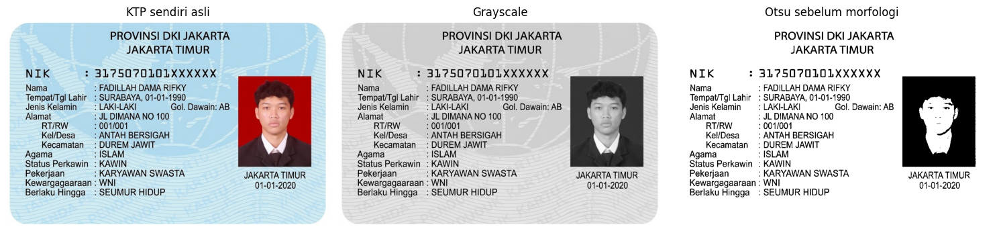

KTP Fulan: ukuran (458, 694), ambang Otsu = 150


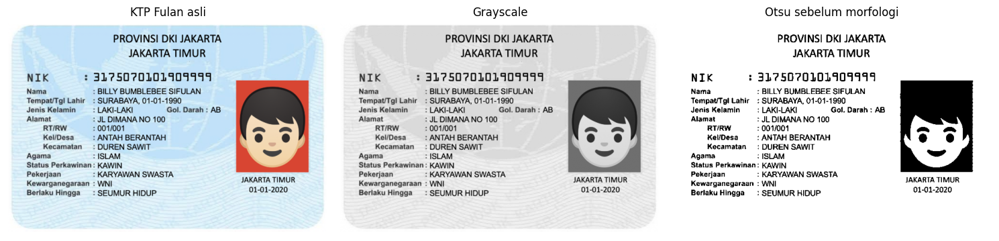

KTP teman: ukuran (676, 1024), ambang Otsu = 127


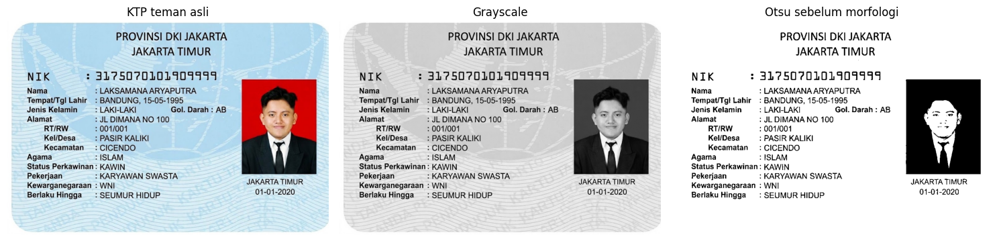

In [ ]:
DAFTAR_KTP = {
    'KTP sendiri': 'ktp_sendiri',
    'KTP Fulan': 'ktp_fulan',
    'KTP teman': 'ktp_teman',
}

data_ktp = {}
for nama, label in DAFTAR_KTP.items():
    bgr = baca_citra(label, grayscale=False)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    ambang, teks = cv2.threshold(
        gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    data_ktp[nama] = {'rgb': rgb, 'gray': gray, 'teks': teks}

    print(f'{nama}: ukuran {gray.shape}, ambang Otsu = {ambang:.0f}')
    tampilkan([rgb, gray, 255 - teks],
              [f'{nama} asli', 'Grayscale', 'Otsu sebelum morfologi'])

### E.1. Perbandingan operasi morfologi pada setiap KTP



KTP sendiri


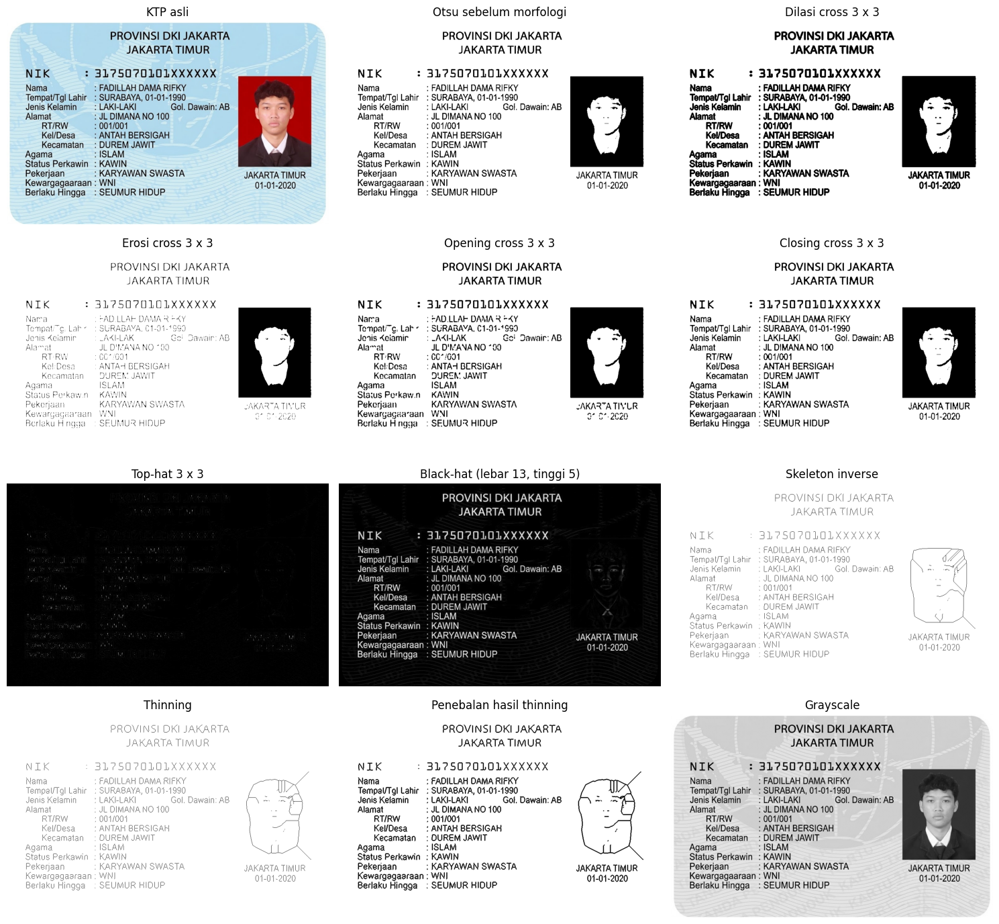

KTP Fulan


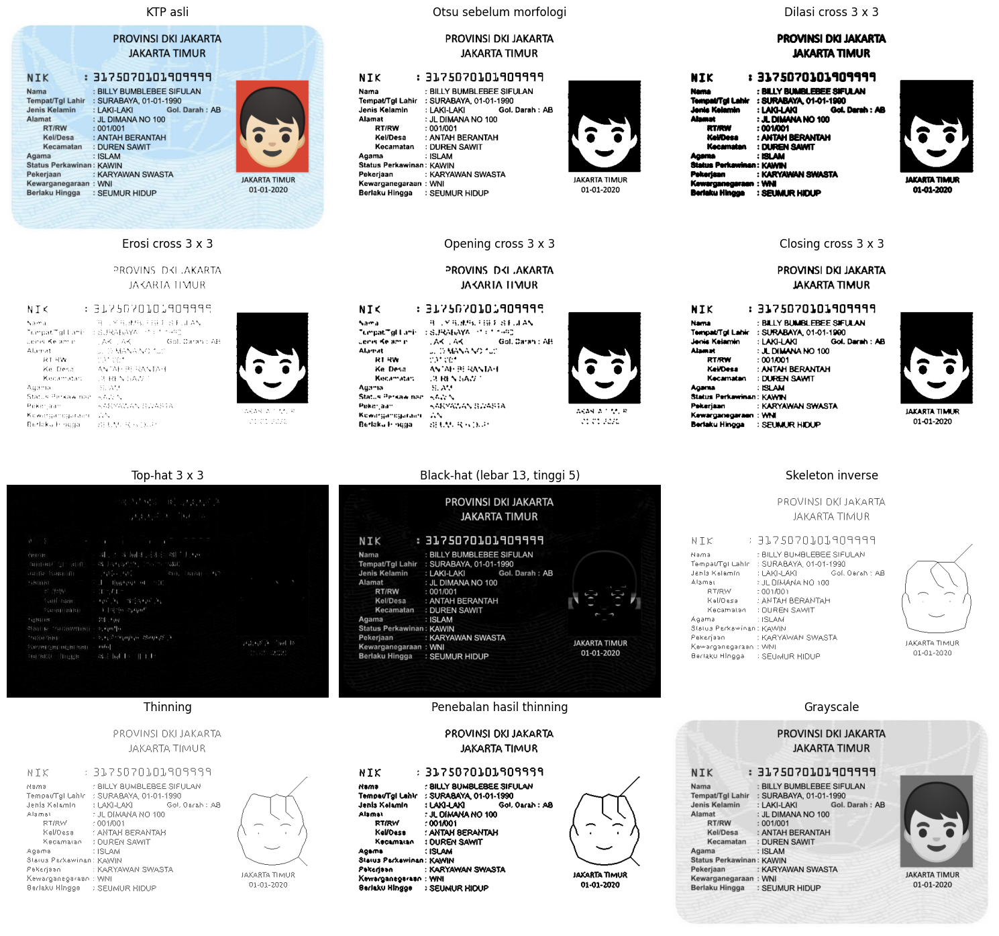

KTP teman


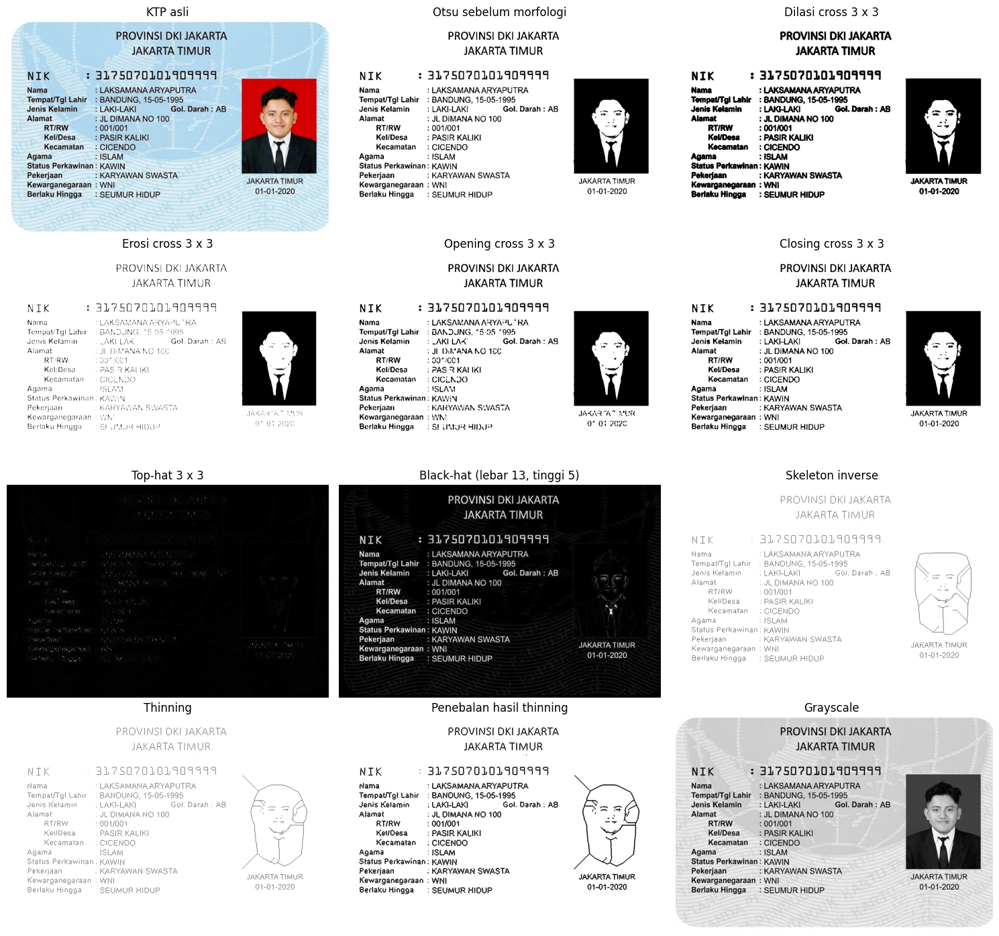

In [23]:
for nama, data in data_ktp.items():
    gray = data['gray']
    teks = data['teks']
    dilasi = cv2.dilate(teks, cross3, iterations=1)
    erosi = cv2.erode(teks, cross3, iterations=1)
    opening = cv2.morphologyEx(teks, cv2.MORPH_OPEN, cross3)
    closing = cv2.morphologyEx(teks, cv2.MORPH_CLOSE, cross3)
    tophat = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, square3)
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel_blackhat)
    skeleton = morphology.skeletonize(teks > 0).astype(np.uint8) * 255
    thin = morphology.thin(teks > 0).astype(np.uint8) * 255
    tebal = cv2.dilate(thin, cross3, iterations=1)

    print(nama)
    tampilkan([data['rgb'], 255 - teks, 255 - dilasi,
               255 - erosi, 255 - opening, 255 - closing,
               tophat, blackhat, 255 - skeleton,
               255 - thin, 255 - tebal, gray],
              ['KTP asli', 'Otsu sebelum morfologi', 'Dilasi cross 3 x 3',
               'Erosi cross 3 x 3', 'Opening cross 3 x 3', 'Closing cross 3 x 3',
               'Top-hat 3 x 3', 'Black-hat (lebar 13, tinggi 5)', 'Skeleton inverse',
               'Thinning', 'Penebalan hasil thinning', 'Grayscale'], kolom=3)

### E.2. Percobaan tambahan: bentuk, ukuran SE, dan iterasi




KTP sendiri - Opening - Square
3 x 3, iterasi 1: 1.90% piksel berubah
3 x 3, iterasi 2: 6.27% piksel berubah
5 x 5, iterasi 1: 6.27% piksel berubah
5 x 5, iterasi 2: 6.47% piksel berubah


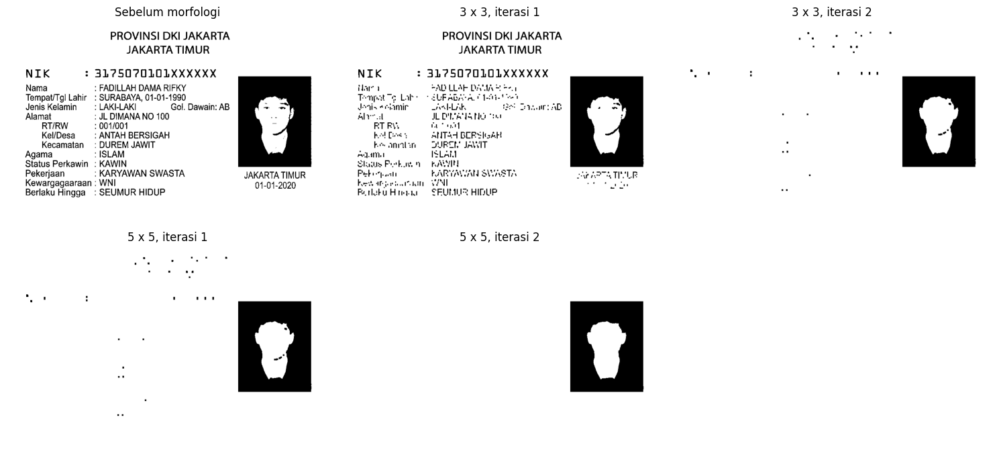


KTP sendiri - Opening - Cross
3 x 3, iterasi 1: 0.71% piksel berubah
3 x 3, iterasi 2: 5.40% piksel berubah
5 x 5, iterasi 1: 5.28% piksel berubah
5 x 5, iterasi 2: 6.46% piksel berubah


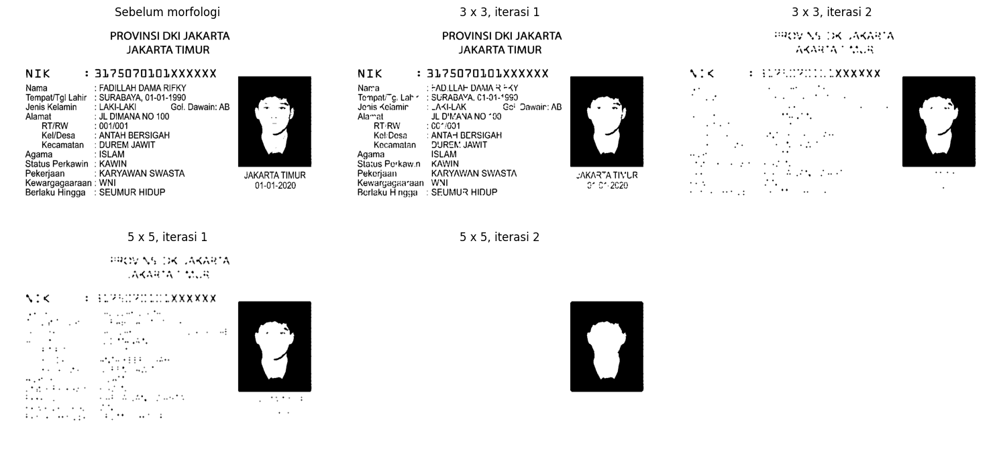


KTP sendiri - Opening - Circular
3 x 3, iterasi 1: 0.71% piksel berubah
3 x 3, iterasi 2: 5.40% piksel berubah
5 x 5, iterasi 1: 5.96% piksel berubah
5 x 5, iterasi 2: 6.47% piksel berubah


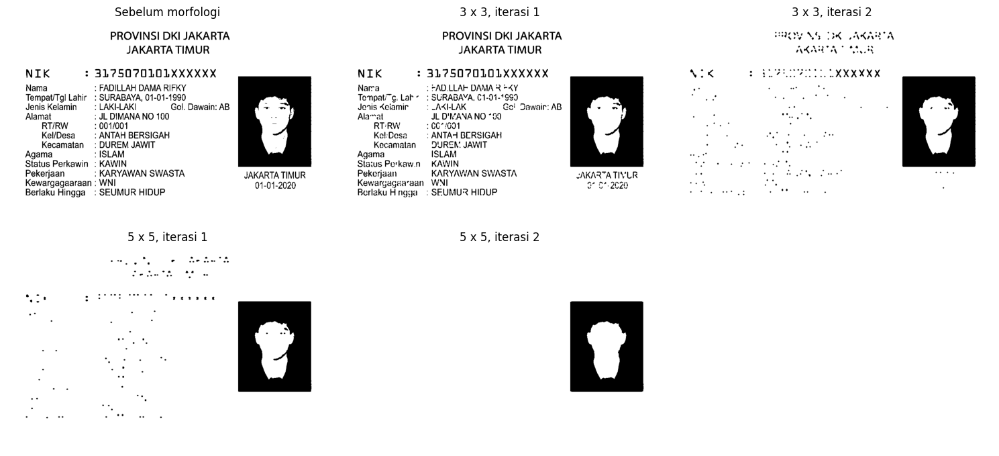


KTP sendiri - Closing - Square
3 x 3, iterasi 1: 0.28% piksel berubah
3 x 3, iterasi 2: 2.13% piksel berubah
5 x 5, iterasi 1: 2.13% piksel berubah
5 x 5, iterasi 2: 6.22% piksel berubah


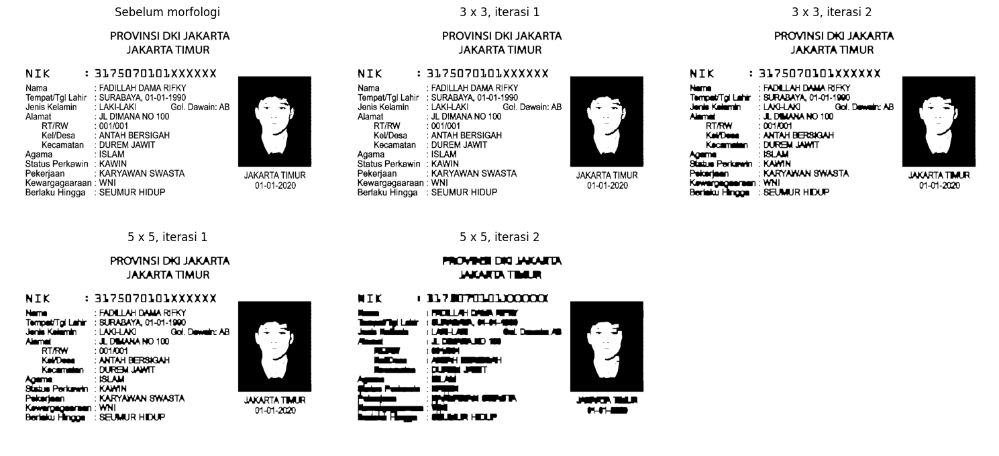


KTP sendiri - Closing - Cross
3 x 3, iterasi 1: 0.20% piksel berubah
3 x 3, iterasi 2: 1.47% piksel berubah
5 x 5, iterasi 1: 1.58% piksel berubah
5 x 5, iterasi 2: 4.61% piksel berubah


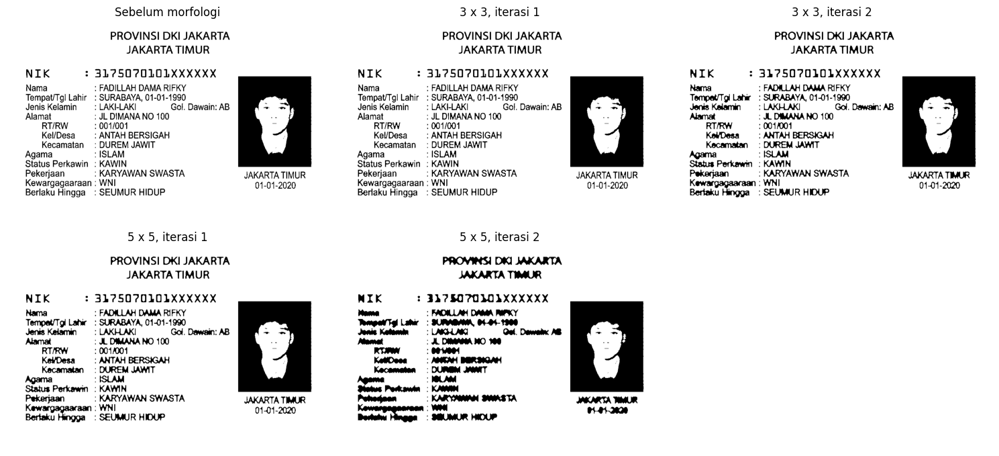


KTP sendiri - Closing - Circular
3 x 3, iterasi 1: 0.20% piksel berubah
3 x 3, iterasi 2: 1.47% piksel berubah
5 x 5, iterasi 1: 1.73% piksel berubah
5 x 5, iterasi 2: 5.26% piksel berubah


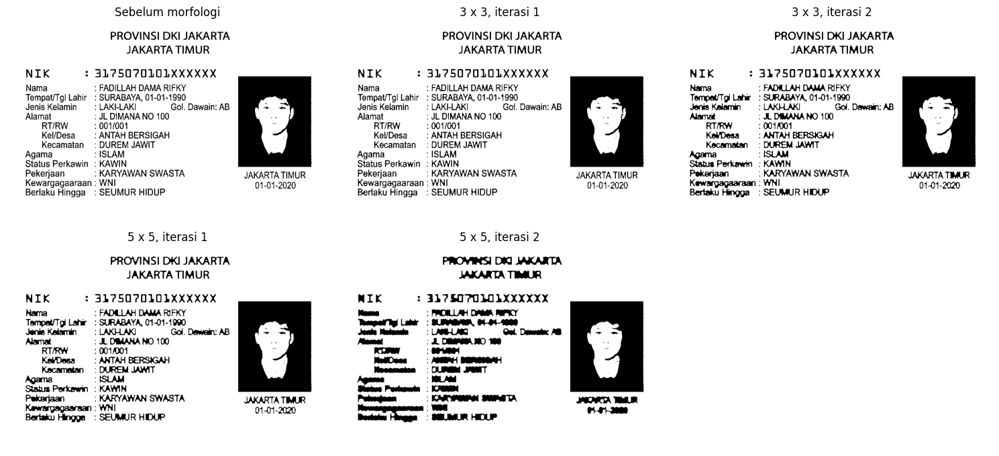


KTP Fulan - Opening - Square
3 x 3, iterasi 1: 3.76% piksel berubah
3 x 3, iterasi 2: 6.09% piksel berubah
5 x 5, iterasi 1: 6.09% piksel berubah
5 x 5, iterasi 2: 6.35% piksel berubah


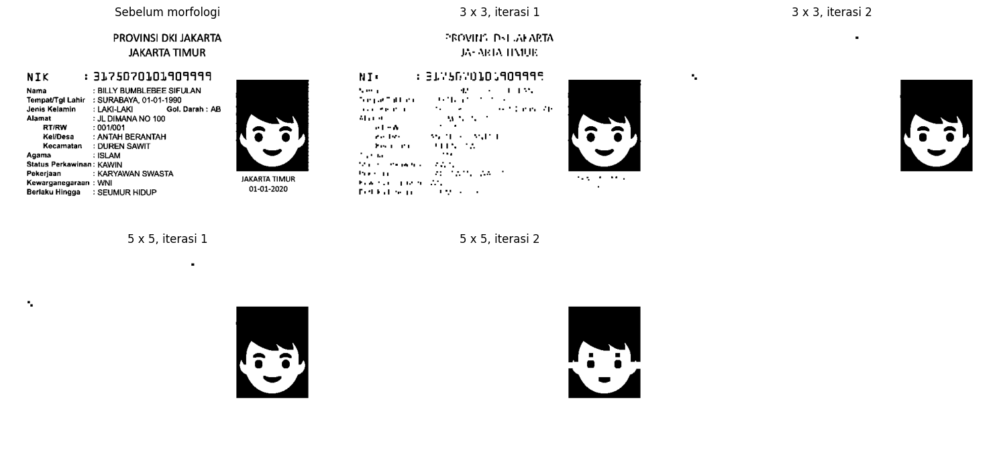


KTP Fulan - Opening - Cross
3 x 3, iterasi 1: 2.13% piksel berubah
3 x 3, iterasi 2: 5.87% piksel berubah
5 x 5, iterasi 1: 5.60% piksel berubah
5 x 5, iterasi 2: 6.21% piksel berubah


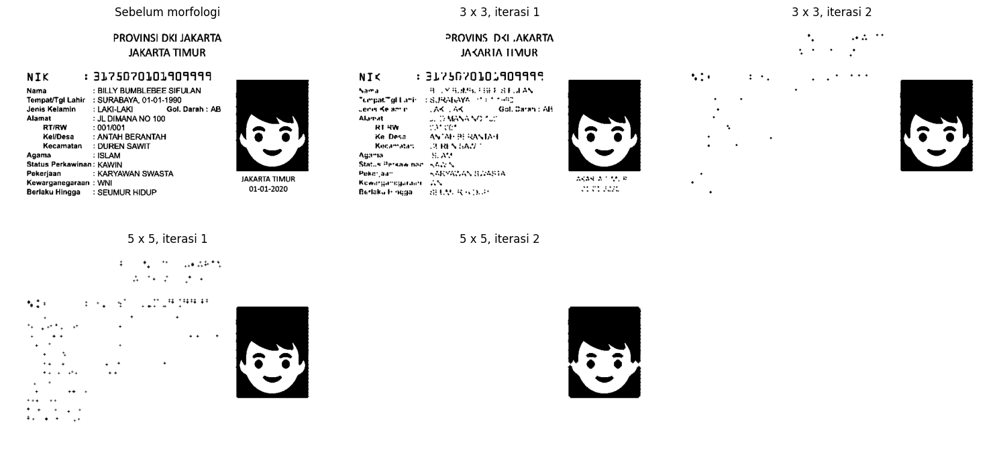


KTP Fulan - Opening - Circular
3 x 3, iterasi 1: 2.13% piksel berubah
3 x 3, iterasi 2: 5.87% piksel berubah
5 x 5, iterasi 1: 6.01% piksel berubah
5 x 5, iterasi 2: 6.25% piksel berubah


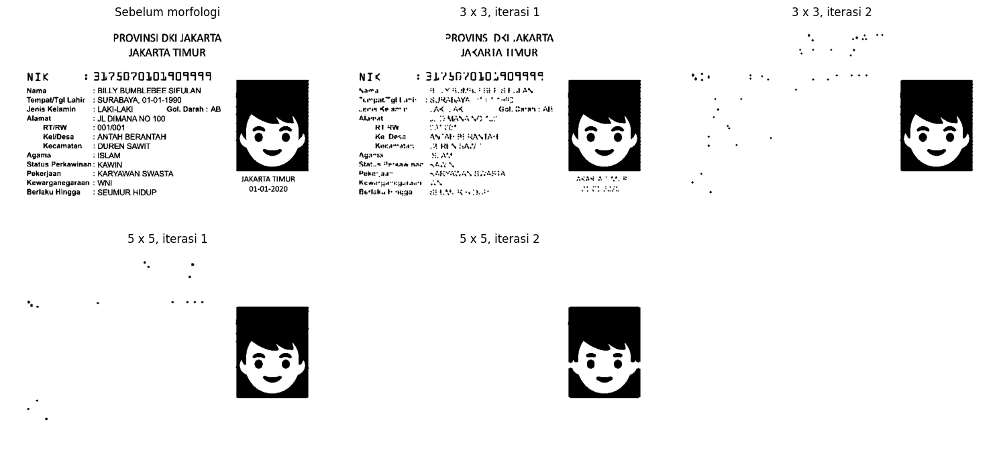


KTP Fulan - Closing - Square
3 x 3, iterasi 1: 1.24% piksel berubah
3 x 3, iterasi 2: 3.53% piksel berubah
5 x 5, iterasi 1: 3.53% piksel berubah
5 x 5, iterasi 2: 8.35% piksel berubah


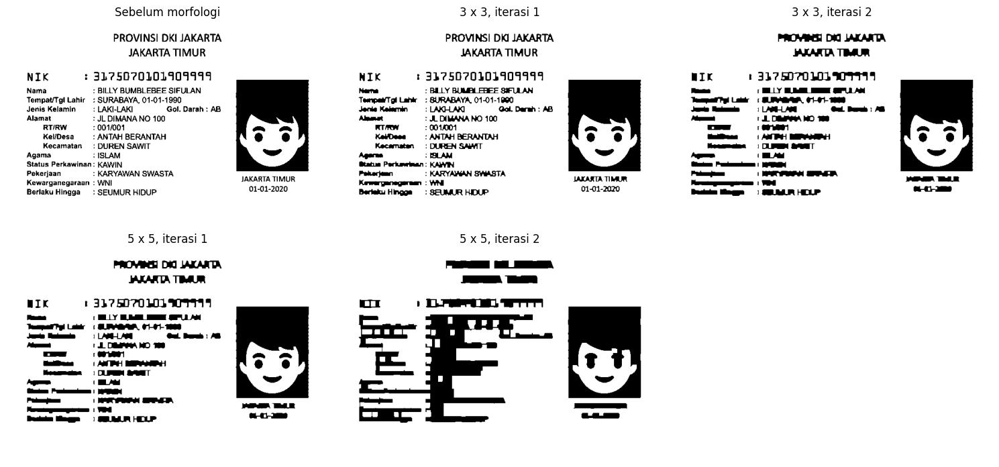


KTP Fulan - Closing - Cross
3 x 3, iterasi 1: 0.90% piksel berubah
3 x 3, iterasi 2: 2.62% piksel berubah
5 x 5, iterasi 1: 2.54% piksel berubah
5 x 5, iterasi 2: 4.07% piksel berubah


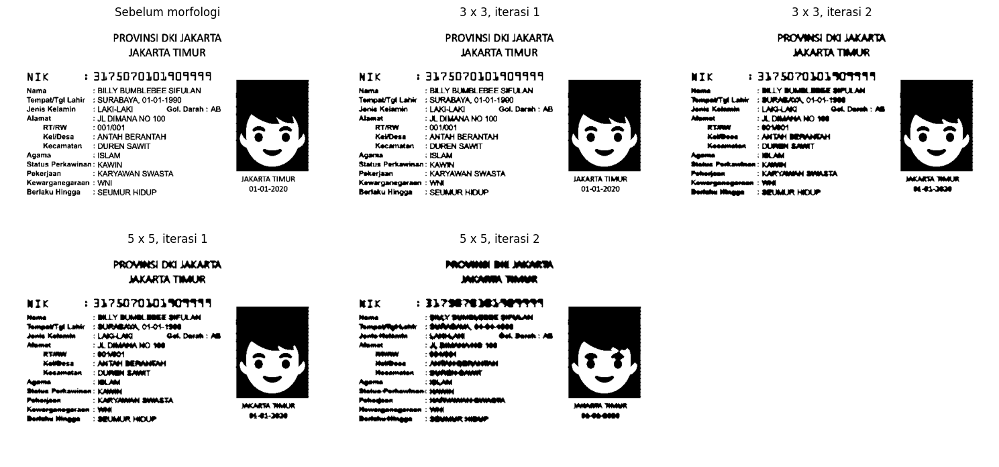


KTP Fulan - Closing - Circular
3 x 3, iterasi 1: 0.90% piksel berubah
3 x 3, iterasi 2: 2.62% piksel berubah
5 x 5, iterasi 1: 3.02% piksel berubah
5 x 5, iterasi 2: 5.26% piksel berubah


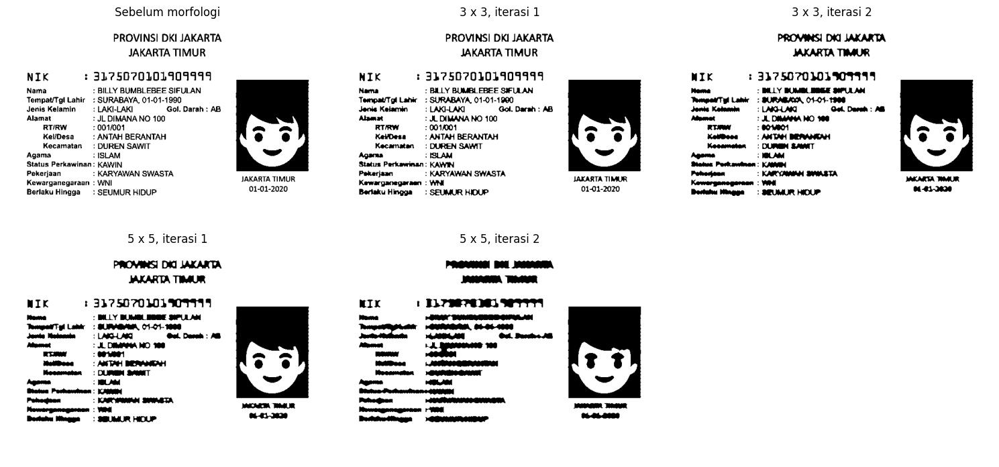


KTP teman - Opening - Square
3 x 3, iterasi 1: 1.57% piksel berubah
3 x 3, iterasi 2: 5.43% piksel berubah
5 x 5, iterasi 1: 5.43% piksel berubah
5 x 5, iterasi 2: 5.55% piksel berubah


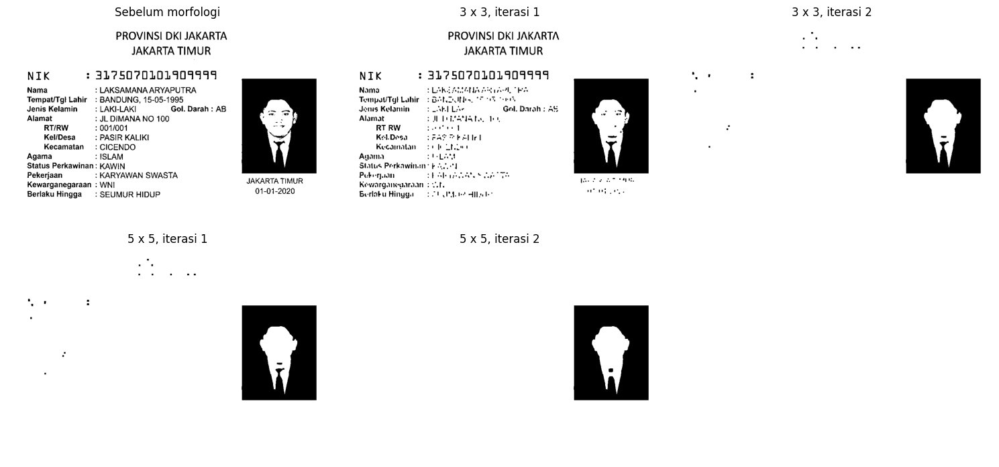


KTP teman - Opening - Cross
3 x 3, iterasi 1: 0.64% piksel berubah
3 x 3, iterasi 2: 4.58% piksel berubah
5 x 5, iterasi 1: 4.47% piksel berubah
5 x 5, iterasi 2: 5.55% piksel berubah


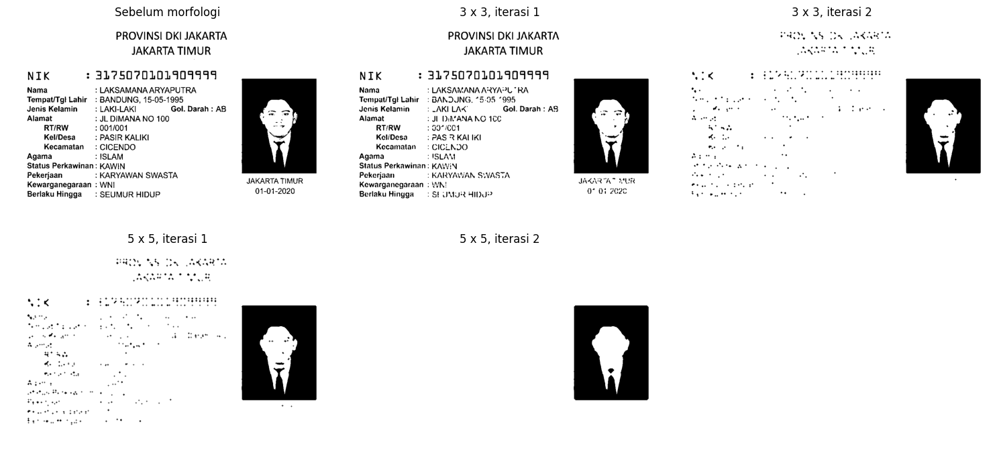


KTP teman - Opening - Circular
3 x 3, iterasi 1: 0.64% piksel berubah
3 x 3, iterasi 2: 4.58% piksel berubah
5 x 5, iterasi 1: 5.06% piksel berubah
5 x 5, iterasi 2: 5.55% piksel berubah


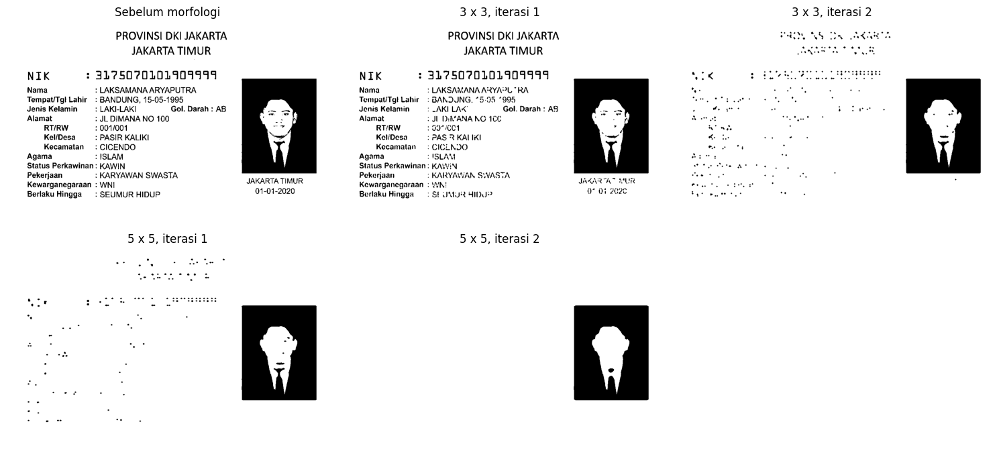


KTP teman - Closing - Square
3 x 3, iterasi 1: 0.36% piksel berubah
3 x 3, iterasi 2: 1.93% piksel berubah
5 x 5, iterasi 1: 1.93% piksel berubah
5 x 5, iterasi 2: 5.18% piksel berubah


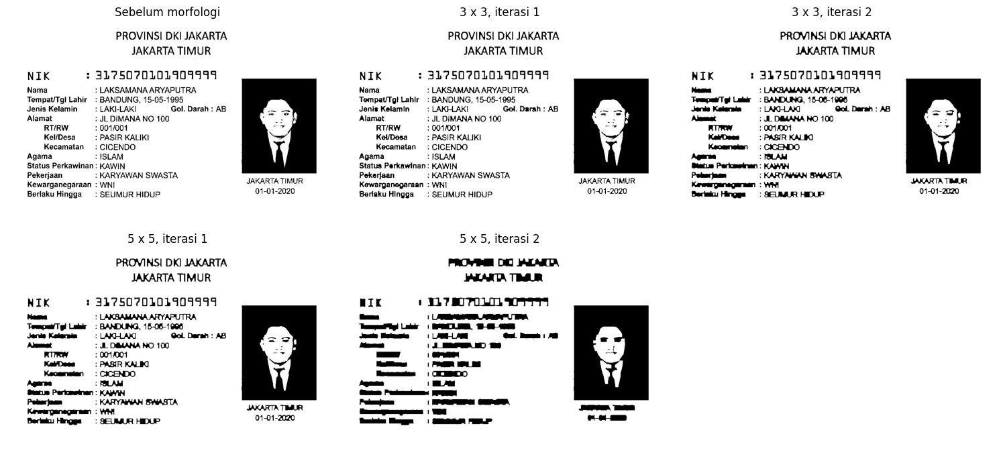


KTP teman - Closing - Cross
3 x 3, iterasi 1: 0.22% piksel berubah
3 x 3, iterasi 2: 1.36% piksel berubah
5 x 5, iterasi 1: 1.42% piksel berubah
5 x 5, iterasi 2: 3.73% piksel berubah


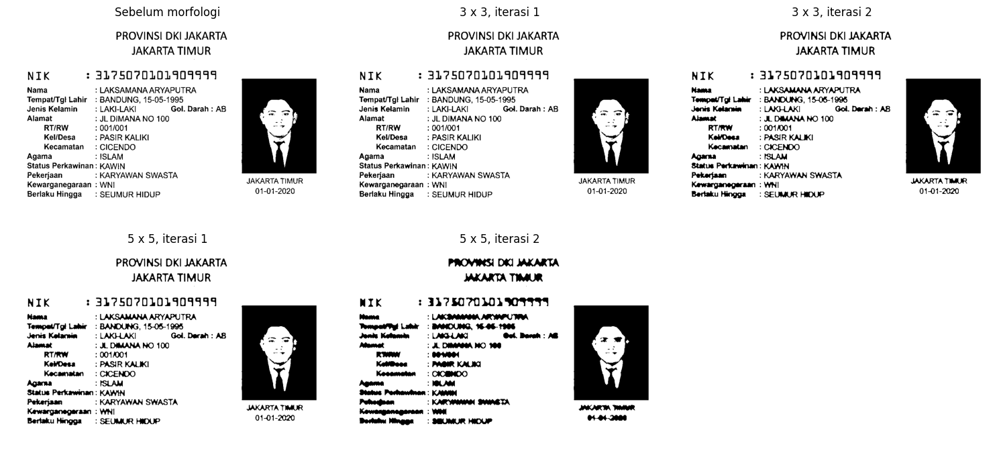


KTP teman - Closing - Circular
3 x 3, iterasi 1: 0.22% piksel berubah
3 x 3, iterasi 2: 1.36% piksel berubah
5 x 5, iterasi 1: 1.63% piksel berubah
5 x 5, iterasi 2: 4.32% piksel berubah


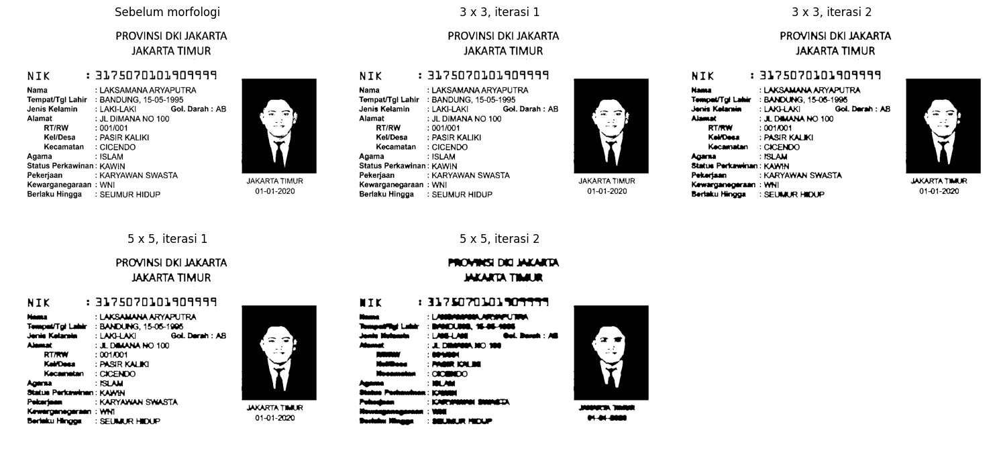

In [24]:
bentuk_se = {
    'Square': cv2.MORPH_RECT,
    'Cross': cv2.MORPH_CROSS,
    'Circular': cv2.MORPH_ELLIPSE,
}
operasi_se = {'Opening': cv2.MORPH_OPEN, 'Closing': cv2.MORPH_CLOSE}

for nama, data in data_ktp.items():
    teks = data['teks']
    for nama_operasi, operasi in operasi_se.items():
        for nama_bentuk, bentuk in bentuk_se.items():
            gambar = [255 - teks]
            judul = ['Sebelum morfologi']
            print(f'\n{nama} - {nama_operasi} - {nama_bentuk}')
            for ukuran in [3, 5]:
                kernel = cv2.getStructuringElement(bentuk, (ukuran, ukuran))
                for iterasi in [1, 2]:
                    hasil = cv2.morphologyEx(teks, operasi, kernel,
                                             iterations=iterasi)
                    persen = np.mean(hasil != teks) * 100
                    nama_uji = f'{ukuran} x {ukuran}, iterasi {iterasi}'
                    print(f'{nama_uji}: {persen:.2f}% piksel berubah')
                    gambar.append(255 - hasil)
                    judul.append(nama_uji)
            tampilkan(gambar, judul, kolom=3)

### E.3. Percobaan tambahan: ukuran kernel black-hat


KTP sendiri


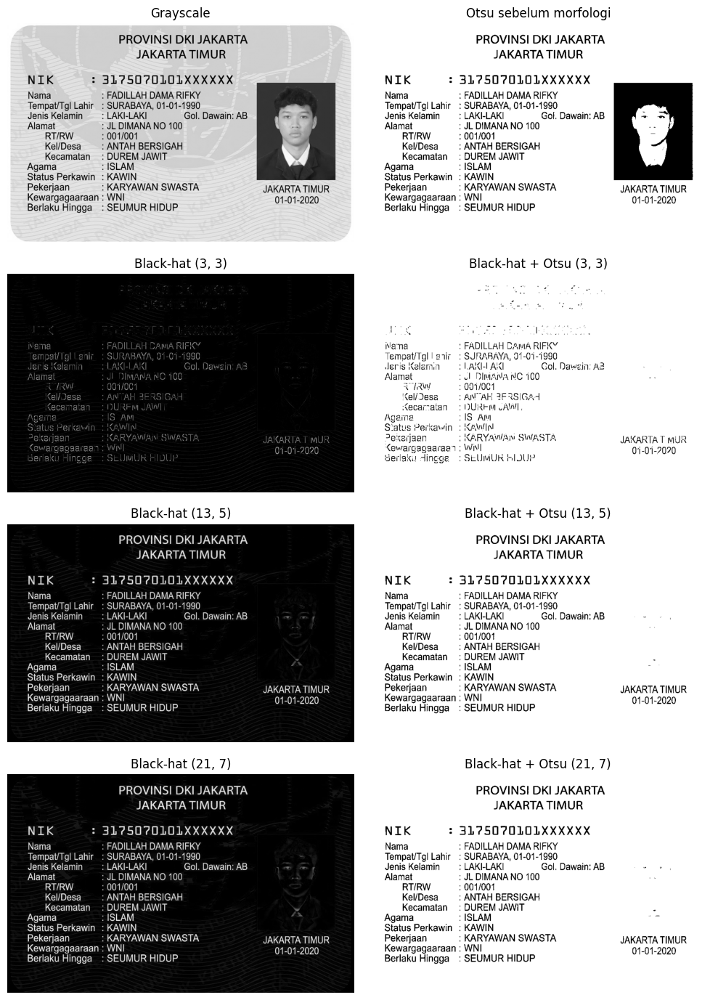

KTP Fulan


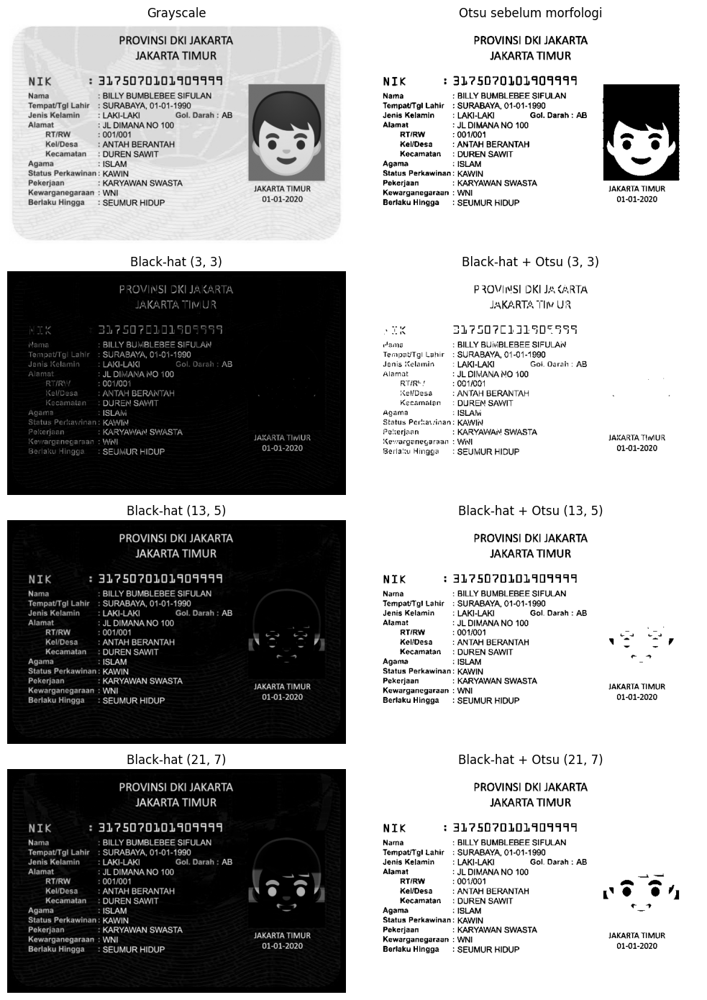

KTP teman


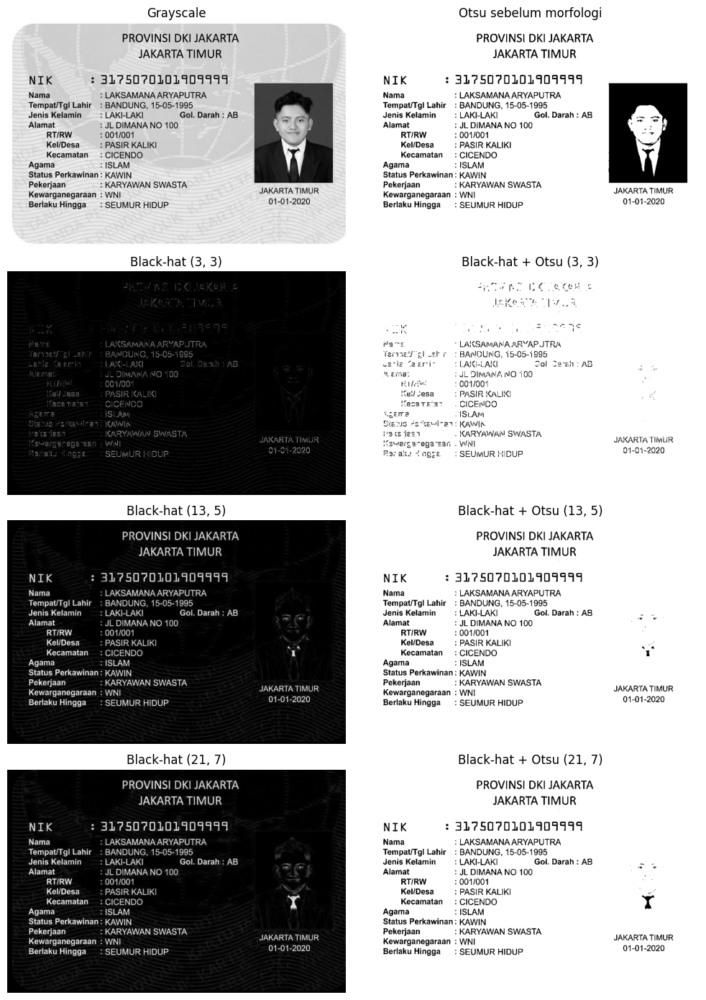

In [25]:
for nama, data in data_ktp.items():
    gambar = [data['gray'], 255 - data['teks']]
    judul = ['Grayscale', 'Otsu sebelum morfologi']
    for lebar, tinggi in [(3, 3), (13, 5), (21, 7)]:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (lebar, tinggi))
        hasil = cv2.morphologyEx(data['gray'], cv2.MORPH_BLACKHAT, kernel)
        _, teks_blackhat = cv2.threshold(
            hasil, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        gambar.extend([hasil, 255 - teks_blackhat])
        judul.extend([f'Black-hat ({lebar}, {tinggi})',
                      f'Black-hat + Otsu ({lebar}, {tinggi})'])
    print(nama)
    tampilkan(gambar, judul, kolom=2)

### E.4. Hasil akhir percobaan yang dapat disesuaikan



KTP sendiri: Closing, Cross, ukuran (3, 3), iterasi 1


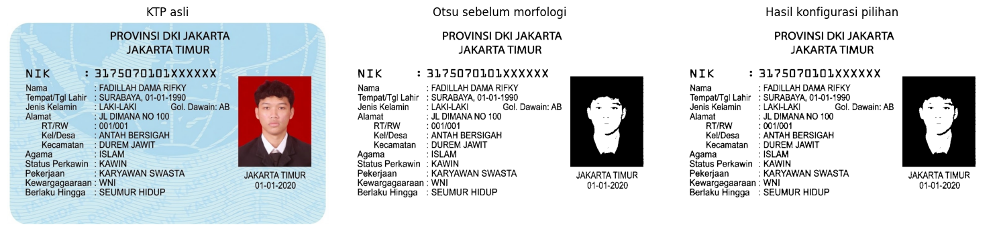

KTP Fulan: Closing, Cross, ukuran (3, 3), iterasi 1


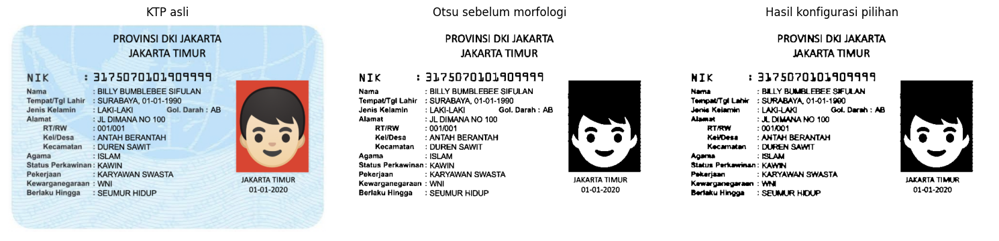

KTP teman: Closing, Cross, ukuran (3, 3), iterasi 1


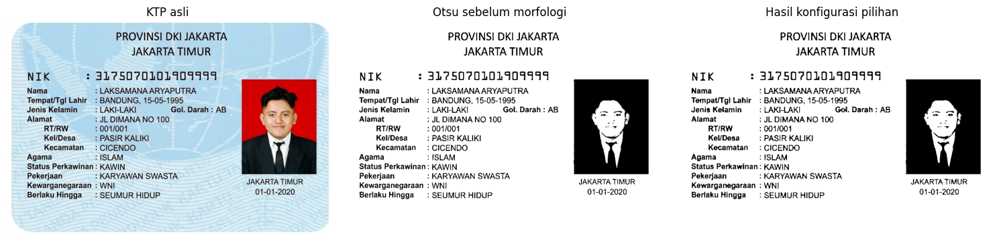

In [26]:
PILIHAN = {
    'KTP sendiri': ('Closing', 'Cross', (3, 3), 1),
    'KTP Fulan': ('Closing', 'Cross', (3, 3), 1),
    'KTP teman': ('Closing', 'Cross', (3, 3), 1),
}

hasil_akhir = {}
for nama, data in data_ktp.items():
    metode, bentuk, ukuran, iterasi = PILIHAN[nama]
    kernel = cv2.getStructuringElement(bentuk_se[bentuk], ukuran)

    if metode == 'Otsu':
        hasil = data['teks'].copy()
    elif metode == 'Blackhat':
        fitur = cv2.morphologyEx(data['gray'], cv2.MORPH_BLACKHAT,
                                 kernel, iterations=iterasi)
        _, hasil = cv2.threshold(
            fitur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        hasil = cv2.morphologyEx(data['teks'], operasi_se[metode],
                                 kernel, iterations=iterasi)

    hasil_akhir[nama] = 255 - hasil
    print(f'{nama}: {metode}, {bentuk}, ukuran {ukuran}, iterasi {iterasi}')
    tampilkan([data['rgb'], 255 - data['teks'], hasil_akhir[nama]],
              ['KTP asli', 'Otsu sebelum morfologi', 'Hasil konfigurasi pilihan'])